# 05 · GRASP

Théorie complète : `docs/theory/02_grasp.md`. Code : `optimizer/algorithms/grasp.py`.

**Schéma** (cours) : $K$ itérations indépendantes. Chacune enchaîne une construction gloutonne randomisée, une recherche locale et une évaluation ; on garde la meilleure solution. Il n'y a **aucune mémoire** entre itérations.

**Construction.** Les qubits sont placés dans le même ordre $i_1, \dots, i_n$ que pour les fourmis. À l'étape $t$ :

$$
c_t(u) = g_t(u) = \sum_{j \in L_t} w_{i_t j}\,\big(d(u, s(j)) - 1\big), \qquad
\mathrm{RCL}_t = \big\lbrace u \in J_t : c_t(u) \le c_t^{\min} + \alpha\,(c_t^{\max} - c_t^{\min}) \big\rbrace, \qquad
s(i_t) \sim \mathcal{U}(\mathrm{RCL}_t)
$$

- **Sans partenaire placé** : $c_t(u) = \max \deg_C - \deg_C(u)$ (centralité).
- **Variante par cardinalité** : $\mathrm{RCL}_t$ = les $k$ plus petits $c_t$.
- **Propriété** : $\sum_t g_t(s(i_t)) = C(s)$, comme pour les fourmis. La construction est un glouton randomisé sur $C$.

**Recherche locale sur $C$ (gratuite).** Descente « meilleure amélioration » dans le voisinage par transposition, jusqu'à un optimum local de $C$. Tous les $\Delta C$ sont calculés d'un coup avec $A = W\,D[s, :]$, où $A_{iv}$ est le coût des arêtes de $i$ si $i$ était sur $v$ :

$$
\Delta C_{\mathrm{dépl.}}(a \to v) = A_{a v} - A_{a\,s(a)}, \qquad
\Delta C_{\mathrm{éch.}}(a, b) = A_{a\,s(b)} - A_{a\,s(a)} + A_{b\,s(a)} - A_{b\,s(b)} + 2\,w_{ab}\,d(s(a), s(b))
$$

Le dernier terme corrige l'arête $\lbrace a, b \rbrace$, dont la distance ne change pas.

**Évaluation.** Une évaluation de $f$ par itération, sauf si le placement a déjà été évalué : il est alors sauté, ce qui ne coûte rien. On obtient jusqu'à $K = B$ itérations.

**Variante `grasp_f`.** Après l'évaluation, une descente échantillonnée sur $f$ :
1. tirer $V$ voisins et évaluer le meilleur selon $C$ ;
2. s'y déplacer si $f$ diminue ;
3. arrêter après $R$ échecs consécutifs.

Chaque itération coûte alors $1 + (\text{pas de descente})$ évaluations.

| Symbole | Code | Base | Rôle |
|---|---|---|---|
| $\alpha$ | `alpha` | 0,2 | taux d'acceptation : 0 = glouton, 1 = aléatoire |
| type de RCL | `rcl`, `cardinality` | par valeur | valeur ($\alpha$) ou cardinalité ($k$) |
| recherche locale | `local_search` | oui | descente sur $C$ jusqu'à l'optimum local |
| $R$, $V$ | `fitness_patience`, `fitness_neighbours` | 0 (désactivée), 20 | descente échantillonnée sur $f$ |

In [1]:
import math
import os
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats  # test de Mann-Whitney

from goc.paths import RESULTS_ROOT, SOLUTIONS_ROOT
from optimizer import Problem, available_instances, distance_cost, history_frame, load_instance, load_results, results_frame, run_grid, save_results, write_solution_if_better
from optimizer.algorithms import grasp
from optimizer.local_search import surrogate_local_optimum
from optimizer.representation import from_mapping, to_mapping

In [2]:
# Réglages communs des graphiques : couleurs, polices, grilles.
import matplotlib as mpl
import matplotlib.pyplot as plt

# Palette de couleurs utilisée pour les séries (une couleur par algorithme ou par instance).
PALETTE = ["#3d72c4", "#d4692b", "#2a8a4f", "#c9443c", "#7a5cc2", "#8a8f98", "#c48a0a", "#2a9fb0", "#b04a8f"]
# Couleurs du cours : orange pour les qubits logiques, bleu pour les qubits physiques.
LOGICAL, LOGICAL_SOFT = "#d4692b", "#fdefe6"
PHYSICAL, PHYSICAL_SOFT = "#3d72c4", "#dfe8f5"
# Couleur selon la distance sur la puce : vert = voisins, jaune = distance 2, rouge = distance 3 ou plus.
DISTANCE_COLORS = {1: "#2a8a4f", 2: "#c48a0a", 3: "#c9443c"}
# Gris pour les textes secondaires et les grilles.
MUTED, GRID = "#656d76", "#e1e4e8"

# Application du style à tous les graphiques matplotlib du notebook.
mpl.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def subplot_grid(count, cols=3, width=4.4, height=3.0):
    """Crée une grille de `count` petits graphiques (cols par ligne) et cache les cases inutilisées."""
    # Nombre de lignes nécessaires (division arrondie au supérieur).
    rows = -(-count // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * width, rows * height), squeeze=False)
    # Les cases en trop (dernière ligne incomplète) sont masquées.
    for ax in axes.ravel()[count:]:
        ax.set_visible(False)
    return fig, axes.ravel()[:count]

## Paramètres

`INSTANCE_ID` est l'instance des sections 1 et 2. Les exécutions sont enregistrées dans `results/grasp/` ; `RECOMPUTE = True` les refait. Les références et les fourmis sont relues dans `results/comparison/` (notebook 99), avec le même budget et les mêmes graines.

In [3]:
# Instance des explications détaillées (sections 1 et 2) et graine.
INSTANCE_ID = 6
SEED = 0
# Budget de vraies évaluations par exécution, graines et instances de la comparaison.
BUDGET = 200
SEEDS = [0, 1, 2, 3, 4]
COMPARISON_INSTANCES = available_instances()
# Études de paramètres : instance 3 (C peu fiable) et 9 (C fiable), 3 graines.
STUDY_INSTANCES = [3, 9]
STUDY_SEEDS = [0, 1, 2]
# Section 1 : nombre de constructions (gratuites) par valeur de alpha.
CONSTRUCTIONS = 200
# Réévaluations des meilleures solutions (section 5).
REEVALUATIONS = 10
WORKERS = max(1, (os.cpu_count() or 2) - 4)
RECOMPUTE = False
CACHE_DIR = RESULTS_ROOT / "grasp"
REFERENCE_DIR = RESULTS_ROOT / "comparison"
GROUP = "Groupe0"
SOLUTIONS_DIR = SOLUTIONS_ROOT

# Réglage de base (identique à celui du notebook 99, pour que les exécutions y soient réutilisées).
BASE = {"alpha": 0.2, "rcl": "value", "local_search": True, "fitness_patience": 0}

In [4]:
def cached_grid(name, algorithms, instance_ids, seeds, budget):
    """Lance run_grid, ou relit le résultat déjà enregistré dans CACHE_DIR/<name>.jsonl."""
    path = CACHE_DIR / f"{name}.jsonl"
    if path.exists() and not RECOMPUTE:
        results = load_results(path)
        print(f"Loaded {len(results)} runs from {path}")
        return results
    results = run_grid(algorithms, instance_ids, seeds, budget, workers=WORKERS)
    save_results(results, path)
    return results


def display_table(frame, value="best_cost"):
    """Pour chaque algorithme et instance : « moyenne ± écart-type (meilleur) » de b_B sur les graines."""
    cells = frame.groupby(["algorithm", "instance_id"], sort=False)[value].agg(lambda s: f"{s.mean():.1f} ± {s.std(ddof=0):.1f} ({s.min():g})")
    return cells.unstack("instance_id").rename(columns=lambda c: f"inst. {c}")

## 1. La construction et la recherche locale (sans évaluation)

### 1.1 Une construction détaillée ($\alpha = 0{,}2$)

Pour chaque étape : coûts extrêmes, seuil $c^{\min} + \alpha(c^{\max} - c^{\min})$, taille de la RCL et coût ajouté par le choix tiré.

On vérifie que $\sum_t g_t = C(s)$. On calcule aussi la probabilité de construire exactement cette solution :

$$
\mathbb{P}(s) = \prod_t \frac{1}{\lvert \mathrm{RCL}_t \rvert}
$$

Plus elle est petite, plus les constructions sont variées.

In [5]:
instance = load_instance(INSTANCE_ID)
constructor = grasp.Constructor(instance)
mapping, steps = constructor.construct(np.random.default_rng(SEED), alpha=BASE["alpha"], record=True)
mapping_array = np.array(mapping)
rows = []
for t, step in enumerate(steps, start=1):
    costs = step["costs"]
    # Coût ajouté par le choix tiré (index du qubit choisi parmi les libres).
    chosen_cost = costs[list(step["free"]).index(step["choice"])]
    rows.append({
        "t": t, "qubit": f"q{step['qubit']}", "free": len(step["free"]),
        "c_min": costs.min(), "c_max": costs.max(),
        "threshold": round(costs.min() + BASE["alpha"] * (costs.max() - costs.min()), 2),
        "|RCL|": len(step["rcl"]), "chosen": f"P{step['choice']}", "c_t(chosen)": chosen_cost,
    })
construction_table = pd.DataFrame(rows).set_index("t")
# Aux étapes sans partenaire placé, c_t est la centralité (pas un coût ajouté) : on ne les compte pas dans la somme des g_t.
with_partners = [t for t, step in enumerate(steps) if (constructor.weights[step["qubit"], [s["qubit"] for s in steps[:t]]] > 0).any()]
added = sum(construction_table["c_t(chosen)"].iloc[with_partners])
log_probability = -np.log10(construction_table["|RCL|"]).sum()
print(f"sum of g_t = {added:g} ; C(s) = {distance_cost(instance, mapping)} ; log10 P(s) = {log_probability:.1f}")
construction_table

sum of g_t = 20 ; C(s) = 20 ; log10 P(s) = -7.6


,qubit,free,c_min,c_max,threshold,|RCL|,chosen,c_t(chosen)
t,,,,,,,,
1,q0,20,0.0,2.0,0.4,10,P16,0.0
2,q10,19,0.0,10.0,2.0,6,P15,0.0
3,q11,18,0.0,10.0,2.0,5,P12,2.0
4,q3,17,0.0,6.0,1.2,3,P7,0.0
5,q2,16,0.0,6.0,1.2,2,P6,0.0
6,q13,15,6.0,18.0,8.4,3,P5,6.0
7,q1,14,0.0,2.0,0.4,6,P1,0.0
8,q9,13,0.0,10.0,2.0,3,P0,0.0
9,q8,12,2.0,12.0,4.0,2,P2,2.0


**Recherche locale sur ce placement.** Chaque pas applique le mouvement de plus petit $\Delta C < 0$. À la fin, tous les $\Delta C$ du voisinage sont $\ge 0$ : c'est un optimum local de $C$.

In [6]:
local_optimum, descent_steps = surrogate_local_optimum(instance, constructor.weights, from_mapping(mapping, instance.m))
print(f"C: {distance_cost(instance, mapping)} -> {distance_cost(instance, local_optimum[:instance.n])} in {descent_steps} best-improvement steps")

C: 20 -> 8 in 3 best-improvement steps


### 1.2 Effet de $\alpha$ : qualité contre diversité

Pour chaque $\alpha$ : `CONSTRUCTIONS` constructions suivies de la recherche locale, sans aucune évaluation de $f$. On mesure :
- **qualité** : $\bar C$ après construction et après recherche locale, et le minimum de $C$ ;
- **diversité** : nombre d'optima locaux **distincts**. C'est le nombre maximal de placements différents que GRASP pourra évaluer (les doublons sont sautés).

**Ce qu'on attend.** Quand $\alpha$ augmente, $\lvert \mathrm{RCL}_t \rvert$ croît, donc la diversité augmente et la qualité de la construction baisse. La recherche locale compense en partie, puisque chaque construction est ramenée à un optimum local.

In [7]:
def alpha_profile(instance_id, alphas, count, seed=0):
    """Qualité et diversité des constructions (+ recherche locale) pour chaque alpha, sans évaluer f."""
    inst = load_instance(instance_id)
    builder = grasp.Constructor(inst)
    rng = np.random.default_rng(seed)
    rows = []
    for alpha in alphas:
        constructed, optimised, rcl_sizes, solutions = [], [], [], set()
        for _ in range(count):
            mapping, steps = builder.construct(rng, alpha, record=True)
            optimum, _ = surrogate_local_optimum(inst, builder.weights, from_mapping(mapping, inst.m))
            constructed.append(distance_cost(inst, mapping))
            optimised.append(distance_cost(inst, optimum[: inst.n]))
            rcl_sizes.append(np.mean([len(s["rcl"]) for s in steps]))
            solutions.add(tuple(int(u) for u in optimum[: inst.n]))
        rows.append({
            "instance": instance_id, "alpha": alpha, "mean |RCL|": round(float(np.mean(rcl_sizes)), 2),
            "mean C constructed": round(float(np.mean(constructed)), 1), "mean C local optimum": round(float(np.mean(optimised)), 1),
            "min C": int(min(optimised)), "distinct local optima": len(solutions),
        })
    return rows


ALPHAS = [0.0, 0.1, 0.2, 0.4, 1.0]
alpha_table = pd.DataFrame([row for i in sorted({INSTANCE_ID, *STUDY_INSTANCES}) for row in alpha_profile(i, ALPHAS, CONSTRUCTIONS)]).set_index(["instance", "alpha"])
alpha_table

mean |RCL|  mean C constructed  mean C local optimum  min C  \
instance alpha                                                                
3        0.0          3.28                60.4                  60.0     60   
         0.1          3.36                60.9                  60.0     60   
         0.2          4.10                63.7                  60.0     60   
         0.4          5.81                71.4                  60.1     60   
         1.0         11.50               115.1                  60.0     60   
6        0.0          3.03                12.8                  11.4      8   
         0.1          3.08                13.0                  11.6      8   
         0.2          3.63                16.3                  13.0      8   
         0.4          6.08                33.3                  15.2      8   
         1.0         13.50                69.0                  14.7      8   
9        0.0          1.68                 8.0                   7.1      4   
         0.1          1.84                10.4                   7.8      4   
         0.2          3.36                23.6                  12.5      4   
         0.4          5.70                40.2                  17.1      6   
         1.0         15.00                95.4                  20.3      6   

                distinct local optima  
instance alpha                         
3        0.0                      194  
         0.1                      196  
         0.2                      199  
         0.4                      199  
         1.0                      200  
6        0.0                      200  
         0.1                      200  
         0.2                      199  
         0.4                      200  
         1.0                      200  
9        0.0                      198  
         0.1                      195  
         0.2                      200  
         0.4                      200  
         1.0                      200

## 2. Une exécution complète (base, instance `INSTANCE_ID`)

À gauche : $f$ de chaque placement évalué (un point par itération) et $b_t$. À droite : $C$ après construction et après recherche locale, itération par itération. Les itérations sautées (doublons) n'apparaissent pas à gauche.

Loaded 1 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\grasp\single_run_instance_6.jsonl
best fitness 25 ; 200 iterations, 0 duplicates skipped, 200 evaluations, 13.7 s


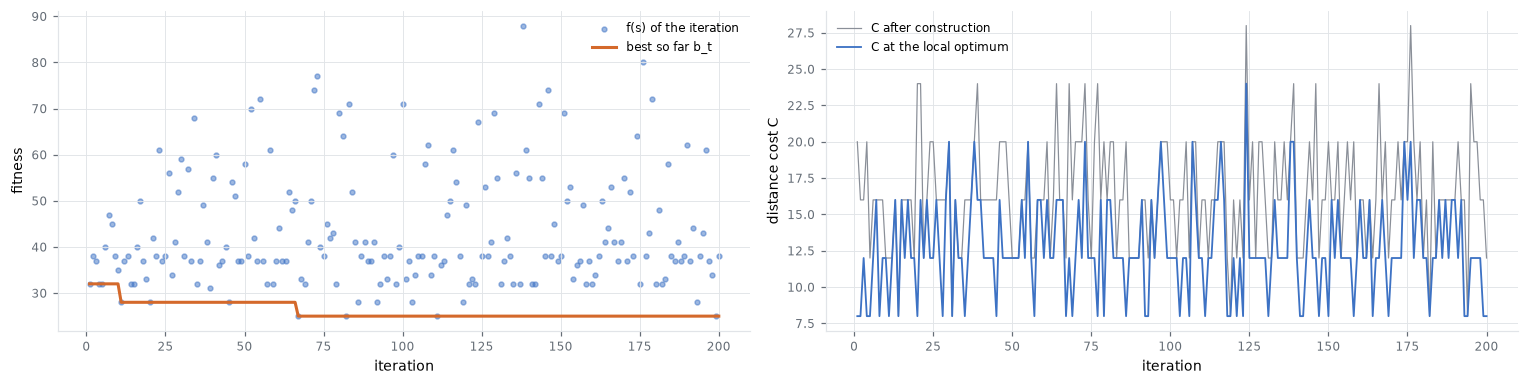

In [8]:
single = cached_grid(f"single_run_instance_{INSTANCE_ID}", {"grasp": (grasp.run, BASE)}, [INSTANCE_ID], [SEED], BUDGET)[0]
iterations = pd.DataFrame(single.trace["iterations"])
print(f"best fitness {single.best_cost} ; {len(iterations)} iterations, {int(iterations['duplicate'].sum())} duplicates skipped, {single.evaluations} evaluations, {single.seconds:.1f} s")


def plot_grasp_run(iterations):
    """f par itération et meilleur courant ; C construit et C optimum local par itération."""
    evaluated = iterations.dropna(subset=["cost"])
    fig, (left, right) = plt.subplots(1, 2, figsize=(14, 3.6))
    left.scatter(evaluated["iteration"], evaluated["cost"], s=10, color=PHYSICAL, alpha=0.5, label="f(s) of the iteration")
    left.plot(evaluated["iteration"], evaluated["cost"].cummin(), color=LOGICAL, linewidth=2, label="best so far b_t")
    left.set_xlabel("iteration")
    left.set_ylabel("fitness")
    left.legend()
    right.plot(iterations["iteration"], iterations["constructed_surrogate"], color=PALETTE[5], linewidth=0.8, label="C after construction")
    right.plot(iterations["iteration"], iterations["local_optimum_surrogate"], color=PALETTE[0], linewidth=1.2, label="C at the local optimum")
    right.set_xlabel("iteration")
    right.set_ylabel("distance cost C")
    right.legend()
    fig.tight_layout()
    return fig


plot_grasp_run(iterations);

**Lecture.** Les itérations sont indépendantes : le nuage de gauche ne « descend » pas comme celui des fourmis, et $b_t$ progresse par paliers, au gré de bons tirages. C'est le régime multi-départ :

$$
\mathbb{P}(\text{au moins un succès en } K \text{ itérations}) = 1 - (1 - q)^K
$$

où $q$ est la probabilité qu'une itération tombe dans la bonne région.

## 3. Effet des paramètres (instances 3 et 9, 3 graines, $B = 200$)

Tableau : `moyenne ± écart-type (meilleur)` de $b_B$. Figure : convergence moyenne $b_t$.

**Résolution.** Les 3 graines par réglage donnent une précision limitée : avec le même réglage, les fourmis variaient d'environ ±5 sur l'instance 3 et d'environ ±2 sur l'instance 9 (notebook 04).

In [9]:
def plot_study(results, title):
    """Convergence moyenne b_t (moyenne sur les graines) de chaque réglage, une colonne par instance."""
    order = list(dict.fromkeys(r.algorithm for r in results))
    instance_ids = sorted({r.instance_id for r in results})
    fig, axes = plt.subplots(1, len(instance_ids), figsize=(5.4 * len(instance_ids), 3.3), squeeze=False)
    for ax, instance_id in zip(axes[0], instance_ids):
        history = history_frame([r for r in results if r.instance_id == instance_id])
        for color, algorithm in zip(PALETTE, order):
            curves = history[history["algorithm"] == algorithm].pivot_table(index="evaluation", columns="seed", values="best").ffill()
            ax.plot(curves.index, curves.mean(axis=1), color=color, label=algorithm, linewidth=1.5)
        ax.set_title(f"Instance {instance_id}")
        ax.set_xlabel("evaluations t", fontsize=8)
        ax.set_ylabel("mean best fitness b_t", fontsize=8)
        ax.legend()
    fig.suptitle(title, y=1.02)
    fig.tight_layout()
    return fig


def study(name, settings):
    """Une exécution par réglage (dictionnaire de paramètres modifiant BASE), instance et graine."""
    algorithms = {label: (grasp.run, {**BASE, **changes}) for label, changes in settings.items()}
    return cached_grid(f"study_{name}", algorithms, STUDY_INSTANCES, STUDY_SEEDS, BUDGET)

### 3.1 Taux d'acceptation $\alpha$

Les deux extrêmes correspondent au cours : $\alpha = 0$ est un glouton suivi d'une recherche locale, avec du hasard seulement entre coûts égaux ; $\alpha = 1$ est un multi-départ aléatoire suivi d'une recherche locale. La section 1.2 donne, pour chaque $\alpha$, le nombre d'optima locaux distincts disponibles.

Loaded 30 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\grasp\study_alpha.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
alpha=0,140.7 ± 2.1 (138),52.3 ± 1.2 (51)
alpha=0.1,127.7 ± 4.6 (123),50.3 ± 1.7 (48)
alpha=0.2,136.3 ± 1.9 (135),54.3 ± 2.5 (51)
alpha=0.4,137.0 ± 5.4 (131),58.0 ± 4.2 (55)
alpha=1,136.0 ± 3.7 (131),59.3 ± 3.3 (55)


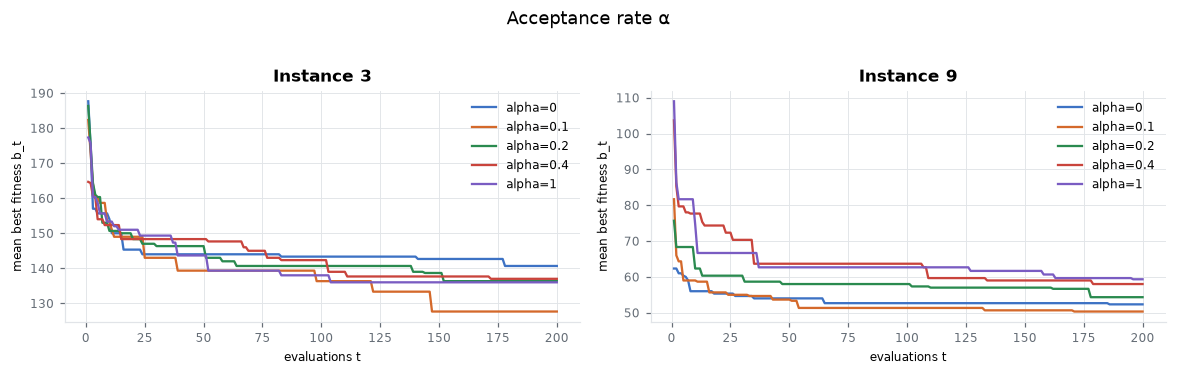

In [10]:
alpha_study = study("alpha", {f"alpha={a:g}": {"alpha": a} for a in [0.0, 0.1, 0.2, 0.4, 1.0]})
display(display_table(results_frame(alpha_study)))
plot_study(alpha_study, "Acceptance rate α");

### 3.2 RCL par valeur ou par cardinalité

Les coûts $c_t$ sont des entiers petits et souvent égaux. Avec un seuil en $\alpha$, $\lvert \mathrm{RCL}_t \rvert$ varie donc par paliers d'une étape à l'autre. La RCL par cardinalité fixe $\lvert \mathrm{RCL}_t \rvert = k$, avec égalités départagées au hasard, ce qui rend la randomisation **uniforme sur les étapes**.

Loaded 24 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\grasp\study_rcl.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
value 0.2,133.3 ± 5.7 (126),52.7 ± 1.7 (51)
k=2,130.7 ± 11.1 (115),50.3 ± 1.7 (48)
k=3,136.3 ± 4.0 (133),55.0 ± 2.4 (52)
k=5,131.3 ± 1.2 (130),58.0 ± 2.9 (54)


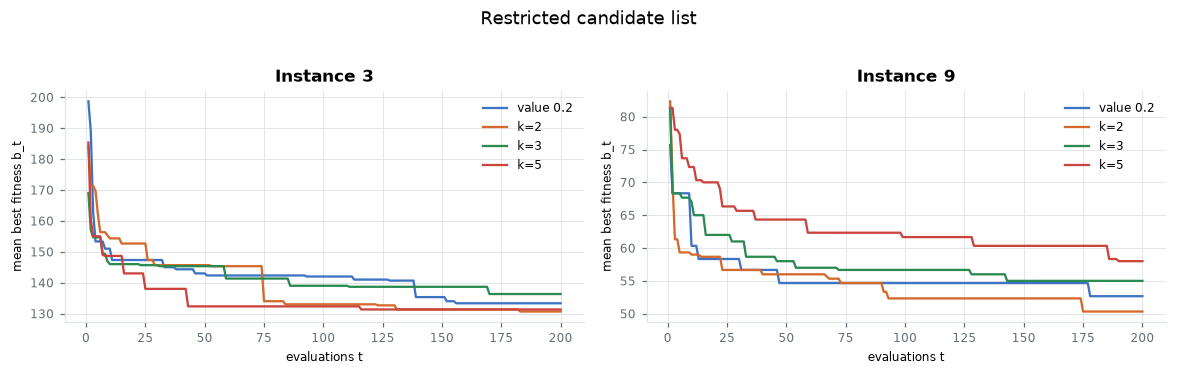

In [11]:
rcl_study = study("rcl", {"value 0.2": {}, "k=2": {"rcl": "cardinality", "cardinality": 2}, "k=3": {"rcl": "cardinality", "cardinality": 3}, "k=5": {"rcl": "cardinality", "cardinality": 5}})
display(display_table(results_frame(rcl_study)))
plot_study(rcl_study, "Restricted candidate list");

### 3.3 Recherche locale

- **Sans recherche locale** : on évalue directement la construction.
- **Sur $C$** (base) : chaque construction est ramenée à un optimum local de $C$, gratuitement.
- **Sur $C$ puis $f$** (`grasp_f`, $R = 3$, $V = 20$) : moins d'itérations ($K < B$), mais chacune affine la vraie fitness.

On attend la descente sur $C$ utile là où $\rho_S(C, f)$ est élevé (instance 9), et la descente sur $f$ là où $C$ guide mal (instance 3).

Loaded 18 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\grasp\study_local_search.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
none,132.3 ± 4.5 (126),58.3 ± 1.9 (57)
C,130.3 ± 3.3 (126),54.7 ± 0.5 (54)
C + f (R=3),135.3 ± 3.8 (130),54.3 ± 4.0 (51)


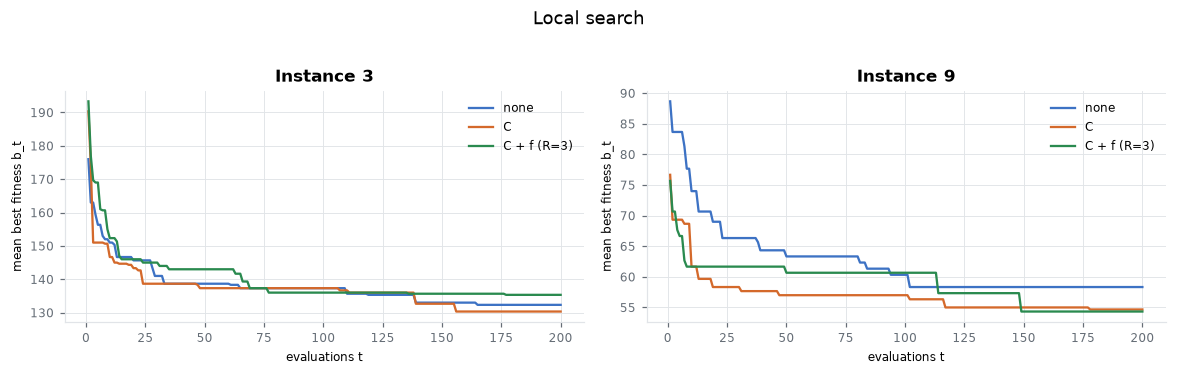

In [12]:
local_study = study("local_search", {"none": {"local_search": False}, "C": {}, "C + f (R=3)": {"fitness_patience": 3}})
display(display_table(results_frame(local_study)))
plot_study(local_study, "Local search");

## 4. Comparaison sur les 9 instances (5 graines, $B = 200$)

- `grasp` : $lpha = 0{,}1$. C'est la meilleure valeur de l'étude 3.1 sur les deux instances, avec un écart supérieur à la résolution de l'étude ; le reste est identique à la base ;
- `grasp_f` : le même réglage, plus la descente sur $f$ ($R = 3$).

Comme $lpha$ a été choisi sur les instances 3 et 9, le résultat sur ces deux instances est légèrement favorisé ; les 7 autres servent de validation.

On compare à `aco_filtered` et aux trois références du notebook 99, relues dans `results/comparison/`.

**Question principale.** GRASP et les fourmis utilisent la même information locale $g_t$. La différence est :
- **la mémoire** : les phéromones, apprises de $f$, pour les fourmis ;
- **la recherche locale** : explicite et sur $C$, pour GRASP.

In [13]:
# Réglage retenu après l'étude 3.1 (identique à celui du notebook 99).
TUNED = {**BASE, "alpha": 0.1}
COMPARISON = {
    "grasp": (grasp.run, TUNED),
    "grasp_f": (grasp.run, {**TUNED, "fitness_patience": 3}),
}
comparison = cached_grid("comparison", COMPARISON, COMPARISON_INSTANCES, SEEDS, BUDGET)
# Références et fourmis du notebook 99, filtrées sur le même budget, les mêmes graines et instances.
others = []
for name in ["identity", "random_search", "surrogate_filtered", "aco_filtered"]:
    path = REFERENCE_DIR / f"{name}.jsonl"
    if path.exists():
        others += [r for r in load_results(path) if r.evaluations == BUDGET and r.seed in SEEDS and r.instance_id in COMPARISON_INSTANCES]
ORDER = ["identity", "random_search", "surrogate_filtered", "aco_filtered", "grasp", "grasp_f"]
frame = results_frame(comparison + others)
display_table(frame).reindex(ORDER)

[9/90] 49 s | last: grasp, instance 4, seed 3 -> 35


[18/90] 107 s | last: grasp, instance 6, seed 2 -> 25


[27/90] 131 s | last: grasp, instance 5, seed 4 -> 324


[36/90] 149 s | last: grasp, instance 8, seed 0 -> 18


[45/90] 157 s | last: grasp, instance 9, seed 3 -> 48


[54/90] 195 s | last: grasp_f, instance 4, seed 3 -> 36


[63/90] 247 s | last: grasp_f, instance 6, seed 2 -> 25


[72/90] 275 s | last: grasp_f, instance 7, seed 1 -> 28


[81/90] 291 s | last: grasp_f, instance 8, seed 0 -> 20


[90/90] 306 s | last: grasp_f, instance 9, seed 3 -> 51


instance_id,inst. 1,inst. 2,inst. 3,inst. 4,inst. 5,inst. 6,inst. 7,inst. 8,inst. 9
algorithm,,,,,,,,,
identity,57.0 ± 0.0 (57),59.0 ± 0.0 (59),141.0 ± 0.0 (141),62.0 ± 0.0 (62),332.2 ± 1.0 (331),78.2 ± 2.4 (77),107.0 ± 0.0 (107),66.8 ± 1.0 (66),137.0 ± 0.0 (137)
random_search,38.4 ± 2.1 (36),90.2 ± 4.5 (86),139.4 ± 5.2 (132),42.4 ± 0.8 (42),334.0 ± 9.0 (323),39.6 ± 3.7 (35),73.6 ± 7.2 (63),40.0 ± 3.8 (34),98.2 ± 3.5 (93)
surrogate_filtered,34.8 ± 1.7 (33),75.8 ± 2.9 (71),140.0 ± 2.2 (137),38.8 ± 1.5 (36),332.0 ± 4.9 (326),33.8 ± 2.1 (31),64.6 ± 6.3 (57),38.4 ± 2.4 (34),90.2 ± 10.4 (79)
aco_filtered,30.0 ± 0.9 (29),59.0 ± 0.0 (59),128.0 ± 5.2 (122),33.8 ± 2.4 (30),323.0 ± 4.4 (317),25.0 ± 0.0 (25),25.2 ± 2.9 (22),21.6 ± 2.0 (19),54.4 ± 2.8 (51)
grasp,29.8 ± 1.5 (27),59.0 ± 0.0 (59),136.0 ± 6.6 (127),34.8 ± 1.7 (32),323.4 ± 3.3 (317),25.0 ± 0.0 (25),22.0 ± 0.0 (22),18.0 ± 0.6 (17),50.2 ± 2.9 (48)
grasp_f,29.6 ± 1.2 (28),59.0 ± 0.0 (59),139.2 ± 2.9 (134),35.6 ± 0.5 (35),324.8 ± 3.2 (320),25.0 ± 0.0 (25),23.8 ± 2.4 (22),19.4 ± 0.5 (19),50.0 ± 1.7 (48)


Rang de la moyenne de $b_B$ sur chaque instance (1 = meilleure), puis rang moyen :

In [14]:
means = frame.groupby(["algorithm", "instance_id"])["best_cost"].mean().unstack().reindex(ORDER)
ranks = means.rank(axis=0, method="min").rename(columns=lambda c: f"inst. {c}")
ranks["mean rank"] = ranks.mean(axis=1).round(2)
ranks.sort_values("mean rank")

instance_id,inst. 1,inst. 2,inst. 3,inst. 4,inst. 5,inst. 6,inst. 7,inst. 8,inst. 9,mean rank
algorithm,,,,,,,,,,
grasp,2.0,1.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.56
aco_filtered,3.0,1.0,1.0,1.0,1.0,1.0,3.0,3.0,3.0,1.89
grasp_f,1.0,1.0,3.0,3.0,3.0,1.0,2.0,2.0,1.0,1.89
surrogate_filtered,4.0,5.0,5.0,4.0,4.0,4.0,4.0,4.0,4.0,4.22
random_search,5.0,6.0,4.0,5.0,6.0,5.0,5.0,5.0,5.0,5.11
identity,6.0,1.0,6.0,6.0,5.0,6.0,6.0,6.0,6.0,5.33


**Tests de Mann-Whitney unilatéraux** (définition dans le notebook 04). Chaque case donne la *p-value* de « la ligne est meilleure que la colonne », instance par instance ; $p < 0{,}05$ indique un avantage fiable.

In [15]:
def significance(frame, algorithm, others):
    """p-values de Mann-Whitney « algorithm est meilleur que other », par instance (lignes) et adversaire (colonnes)."""
    rows = {}
    for instance_id in sorted(frame["instance_id"].unique()):
        subset = frame[frame["instance_id"] == instance_id]
        target = subset.loc[subset["algorithm"] == algorithm, "best_cost"]
        rows[f"inst. {instance_id}"] = {other: stats.mannwhitneyu(target, subset.loc[subset["algorithm"] == other, "best_cost"], alternative="less").pvalue for other in others}
    return pd.DataFrame(rows).T.round(4)


grasp_better = significance(frame, "grasp", ["surrogate_filtered", "aco_filtered", "grasp_f"])
aco_better = significance(frame, "aco_filtered", ["grasp", "grasp_f"])
print("grasp better than ...")
display(grasp_better)
print("aco_filtered better than ...")
display(aco_better)

grasp better than ...


,surrogate_filtered,aco_filtered,grasp_f
inst. 1,0.0057,0.5867,0.6678
inst. 2,0.0037,1.0000,1.0000
inst. 3,0.2648,0.9524,0.3366
inst. 4,0.0134,0.7384,0.2926
inst. 5,0.0098,0.5421,0.4136
inst. 6,0.0037,1.0000,1.0000
inst. 7,0.0036,0.0360,0.0899
inst. 8,0.0056,0.0072,0.0107
inst. 9,0.0056,0.0443,0.5447


aco_filtered better than ...


,grasp,grasp_f
inst. 1,0.5000,0.7481
inst. 2,1.0000,1.0000
inst. 3,0.0754,0.0106
inst. 4,0.3352,0.1830
inst. 5,0.5421,0.3371
inst. 6,1.0000,1.0000
inst. 7,0.9801,0.8153
inst. 8,0.9961,0.9803
inst. 9,0.9723,0.9746


## 5. Meilleures solutions

Pour chaque instance, on prend le meilleur $s^{\mathrm{bs}}$ des variantes GRASP et on le réévalue `REEVALUATIONS` fois pour estimer $F(s^{\mathrm{bs}})$. Le fichier solution n'est écrit que s'il bat celui déjà présent dans `solutions/`.

In [16]:
rows = []
for instance_id in COMPARISON_INSTANCES:
    best = min((r for r in comparison if r.instance_id == instance_id), key=lambda r: r.best_cost)
    checks = Problem(load_instance(instance_id)).fitness_samples(best.best_mapping, REEVALUATIONS)
    cost = min(best.best_cost, min(checks))
    path, written, previous = write_solution_if_better(best.best_mapping, cost, instance_id, group=GROUP, directory=SOLUTIONS_DIR)
    rows.append({
        "instance": instance_id, "algorithm": best.algorithm, "seed": best.seed,
        "cost during search": best.best_cost, "re-evaluation mean": round(float(np.mean(checks)), 2),
        "re-evaluation std": round(float(np.std(checks)), 2),
        "file status": "written" if written else f"kept (existing cost {previous:g})",
        "mapping": " ".join(map(str, best.best_mapping)),
    })
best_solutions = pd.DataFrame(rows).set_index("instance")
best_solutions

,algorithm,seed,cost during search,re-evaluation mean,re-evaluation std,file status,mapping
instance,,,,,,,
1,grasp,0,27,32.6,2.80,kept (existing cost 25),14 12 2 11 1 3 15 0 10 4 5 13
2,grasp,0,59,59.0,0.00,kept (existing cost 59),14 13 12 11 10 9 8 7 6 5 4 3 2 1 0 15
3,grasp,0,127,129.2,6.37,kept (existing cost 115),1 2 13 15 11 4 0 12 3 14
4,grasp,4,32,32.0,0.00,kept (existing cost 30),7 12 6 8 11 1 13 3 5 9 14 10 0 18 2 16 4 19 15
5,grasp,2,317,333.2,2.32,kept (existing cost 316),18 13 12 6 8 3 0 5 4 7 1 2
6,grasp,0,25,25.0,0.00,kept (existing cost 25),7 16 10 5 3 2 1 4 18 17 12 6 15 11
7,grasp,0,22,22.0,0.00,kept (existing cost 22),4 1 2 3 5 8 11 14 16 19 22 25 24 23 21 18 15 1...
8,grasp,1,17,18.2,1.33,kept (existing cost 17),22 19 18 21 14 13 1 2 25 24 23 3 17 12 15 0 26...
9,grasp,1,48,50.4,2.62,written,6 12 13 14 11 8 5 3 2 1 4 7 10 15 18 17 21 23 ...


## Conclusions

_Exécution du 22/11/2026 : $B = 200$, 5 graines, 9 instances. Les références et `aco_filtered` sont relues du notebook 99, avec les mêmes graines._

### Résultat principal

`grasp` ($\alpha = 0{,}1$) a le meilleur rang moyen (1,56), devant `aco_filtered` et `grasp_f` (1,89 chacun).

| | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| `aco_filtered` | 30,0 | 59,0 | **128,0** | **33,8** | **323,0** | 25,0 | 25,2 | 21,6 | 54,4 |
| `grasp` | **29,8** | 59,0 | 136,0 | 34,8 | 323,4 | 25,0 | **22,0** | **18,0** | **50,2** |
| $p$ (`grasp` meilleur) | 0,59 | 1 | 0,95 | 0,74 | 0,54 | 1 | **0,036** | **0,007** | **0,044** |

- **`grasp` est significativement meilleur que les fourmis sur 7, 8 et 9.** Les fourmis ne sont significativement meilleures sur aucune instance ; l'écart le plus net est sur l'instance 3 ($p = 0{,}075$).
- **`grasp` bat `surrogate_filtered`** sur 8 instances sur 9, mais pas sur l'instance 3.

### Interprétation : mémoire contre recherche locale

Les deux méthodes utilisent la même information locale $g_t$ ; ce qui les sépare, c'est l'usage de $C$ et la mémoire.

- **Instances 7, 8 et 9** ($\rho_S \ge 0{,}74$). L'optimum local exact de $C$ est un très bon point de départ, et GRASP l'obtient gratuitement à chaque itération. La colonie doit l'approcher par apprentissage des phéromones, en 40 itérations seulement. Avec un $C$ fiable, **la recherche locale exacte bat la mémoire**.
- **Instance 3** (QFT). La section 1.2 montre que tous les optima locaux de $C$ valent 60 : $C$ est sur un plateau et ne distingue plus les placements. Les itérations GRASP deviennent des tirages au hasard sur ce plateau, sans rien apprendre de $f$. Les phéromones, elles, accumulent l'information de $f$, d'où l'avantage des fourmis (128,0 contre 136,0), non significatif avec 5 graines.
- **Instance 2.** Les deux méthodes trouvent 59, l'optimum présumé.

### Paramètres (instances 3 et 9)

- **$\alpha$.** Sur l'instance 9, l'optimum local moyen de $C$ passe de 7,1 ($\alpha = 0$) à 20,3 ($\alpha = 1$), et la fitness suit : 50,3 pour $\alpha = 0{,}1$ contre 59,3 pour $\alpha = 1$. La diversité n'est pas un problème, même pour $\alpha = 0$ : les égalités de coûts entiers donnent environ 195 optima distincts sur 200 constructions. Un $\alpha$ petit, proche de 0 mais pas nul, est le bon réglage, conformément au cours. Sur l'instance 3, $\alpha = 0{,}1$ est aussi le meilleur (127,7) et $\alpha = 0$ le pire (140,7).
- **Type de RCL.** La cardinalité $k = 2$ égale $\alpha = 0{,}1$ (50,3 sur l'instance 9) ; $k = 5$ est moins bon (58,0). La règle est la même : une RCL petite.
- **Recherche locale sur $C$.** Sur l'instance 9, elle fait passer de 58,3 (sans recherche locale) à 54,7, un écart supérieur à la résolution. Sur l'instance 3, il n'y a aucun effet (plateau).
- **Descente sur $f$ (`grasp_f`).** Elle n'apporte rien : `grasp_f` n'est jamais significativement meilleur que `grasp`, et il est moins bon sur l'instance 8 ($p = 0{,}011$). Chaque pas coûte une évaluation et réduit le nombre de départs $K$, et le bruit rend l'acceptation $f(s') < f(s)$ peu fiable. Avec $B = 200$, **multiplier les départs vaut mieux qu'affiner sur $f$**.

### Limites

- **Choix de $\alpha$.** Il a été fait sur les instances 3 et 9, qui sont aussi dans la comparaison. Les 7 autres instances servent de validation : `grasp` y est 1er ou ex æquo sur 1, 2, 6, 7 et 8.
- **Malédiction du vainqueur.** Sur l'instance 1, la solution vaut 27 pendant la recherche mais 32,6 en moyenne à la réévaluation ; sur l'instance 5, 317 contre 333,2.

### Fichiers solutions

- **Instance 9 :** 48, contre 51 auparavant (réévaluation moyenne 50,4).
- **Instance 3 :** 115, contre 122 auparavant. Ce placement vient de la première exécution de la comparaison, faite avec $\alpha = 0{,}2$ et remplacée depuis. Sa réévaluation moyenne était 127,9, contre environ 140 pour l'ancien placement : il est réellement meilleur.